# Coating layer analysis: demo

Many coatings consist of several layers that look almost identical in a cross-section micrograph. What differs between them is the **size (and number) of the particles** inside: pores, inclusions or precipitates. This notebook walks through the method step by step on a synthetic cross-section where the true layers are known, then shows how to run it on your own images.

**Steps:** particles → substrate interface → depth profile → number of layers (model selection) → wavy boundaries → thickness, areas and particle statistics per layer.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from layer_analysis import Params, analyze, load_gray, segment_particles, detect_substrate
from make_synthetic import load_truth
from plot import plot_analysis, plot_truth_comparison, depth_statistics

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90

## 1. The image
A synthetic cross-section (`make_synthetic.py`): three coating layers with median particle sizes of 0.45, 0.30 and 0.20 µm, wavy boundaries, a particle-free substrate with polishing scratches, blur and noise. The top layer also has a size gradient (particles get smaller with depth), which real coatings often show. Calibration: 16.5 px per µm.

1024 x 544 px = 62.1 x 33.0 µm,  true number of layers: 3


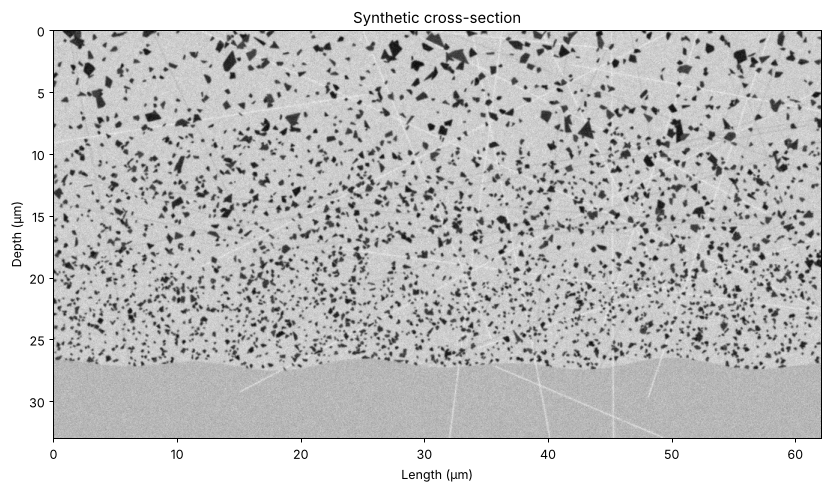

In [2]:
PX_PER_UM = 16.5
gray = load_gray("demo/cross_section.png")
truth = load_truth("demo/cross_section.png")
H, W = gray.shape
print(f"{W} x {H} px = {W / PX_PER_UM:.1f} x {H / PX_PER_UM:.1f} µm,  true number of layers: {truth['n_layers']}")
plt.figure(figsize=(11, 6))
plt.imshow(gray, cmap="gray", extent=[0, W / PX_PER_UM, H / PX_PER_UM, 0])
plt.xlabel("Length (µm)"); plt.ylabel("Depth (µm)"); plt.title("Synthetic cross-section");

## 2. Particles and substrate
Dark objects are segmented with Otsu's threshold and measured (equivalent diameter). The substrate interface is found column by column: above it, the image has many particles and strong texture; below it, the substrate is smooth. The coarse position is then moved to the strongest vertical intensity gradient nearby.

2177 particles detected
Substrate interface error: 0.12 µm


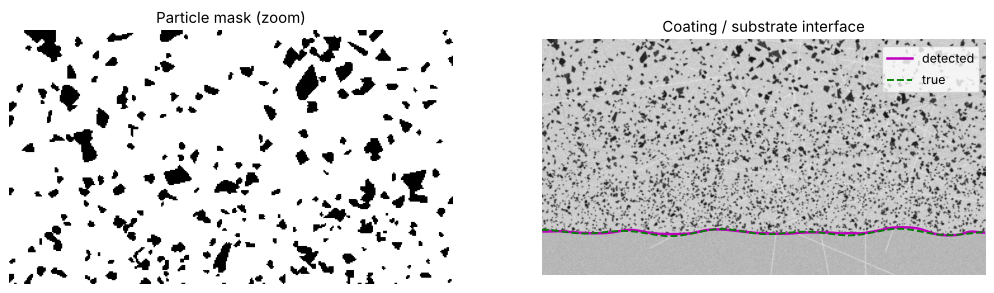

In [3]:
p = Params(px_per_um=PX_PER_UM)
binary, particles = segment_particles(gray, p)
sub_x, sub_y = detect_substrate(gray, binary, p)
print(f"{len(particles)} particles detected")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].imshow(binary[:200, :350], cmap="gray_r"); ax[0].set_title("Particle mask (zoom)"); ax[0].axis("off")
ax[1].imshow(gray, cmap="gray"); ax[1].plot(sub_x, sub_y, "m", lw=2, label="detected")
ax[1].plot(truth["substrate"], "g--", lw=1.5, label="true"); ax[1].legend(); ax[1].axis("off")
ax[1].set_title("Coating / substrate interface")
err = np.abs(np.interp(np.arange(W), sub_x, sub_y) - truth["substrate"]).mean() / PX_PER_UM
print(f"Substrate interface error: {err:.2f} µm")

## 3. What changes with depth?
Particle size (median) and particle density in thin depth bins. Both change at the layer boundaries: smaller particles are also more numerous, so the method uses **both signals**. The median is used instead of the mean because a few large particles would distort the mean.

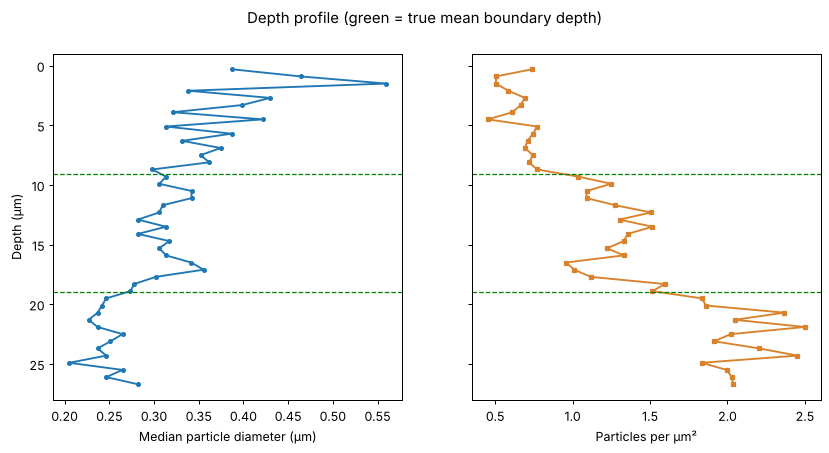

In [4]:
res = analyze(gray, p)
yc, size, dens = depth_statistics(res)
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ax[0].plot(size, yc, "o-", ms=3); ax[0].set_xlabel("Median particle diameter (µm)"); ax[0].set_ylabel("Depth (µm)")
ax[1].plot(dens, yc, "s-", ms=3, color="#d9822b"); ax[1].set_xlabel("Particles per µm²")
for a in ax:
    for b in truth["boundaries"]:
        a.axhline(b.mean() / PX_PER_UM, color="g", ls="--", lw=1)
ax[0].invert_yaxis(); fig.suptitle("Depth profile (green = true mean boundary depth)");

## 4. How many layers?
For 1 to 5 layers, the wavy boundaries are fitted and the model is scored with the **Bayesian Information Criterion** on the individual particles: inside each layer, log-diameters are Gaussian and particle positions follow a Poisson process. Lower BIC = better trade-off between fit and complexity.

A model is only accepted if it is physically plausible: every layer is at least 1 µm thick, and neighbouring layers differ by at least 15 % in median particle size or 30 % in particle density. This stops the method from splitting a single layer that has a gradual size gradient into several layers.

In [5]:
pd.Series(res.bic, name="BIC (NaN = not plausible)").to_frame().round(1)

,BIC (NaN = not plausible)
1,24359.2
2,23915.5
3,23710.2
4,23784.2
5,NaN


In [6]:
print(f"Chosen: {res.n_layers} layers (true: {truth['n_layers']})")

Chosen: 3 layers (true: 3)


## 5. Full result
Boundaries are refined along the cross-section: at 60 positions, the particles in an overlapping window are sorted by depth and the boundary is placed where the likelihood of "smaller/denser below, larger/sparser above" (or the opposite) is highest. The curve is then smoothed.

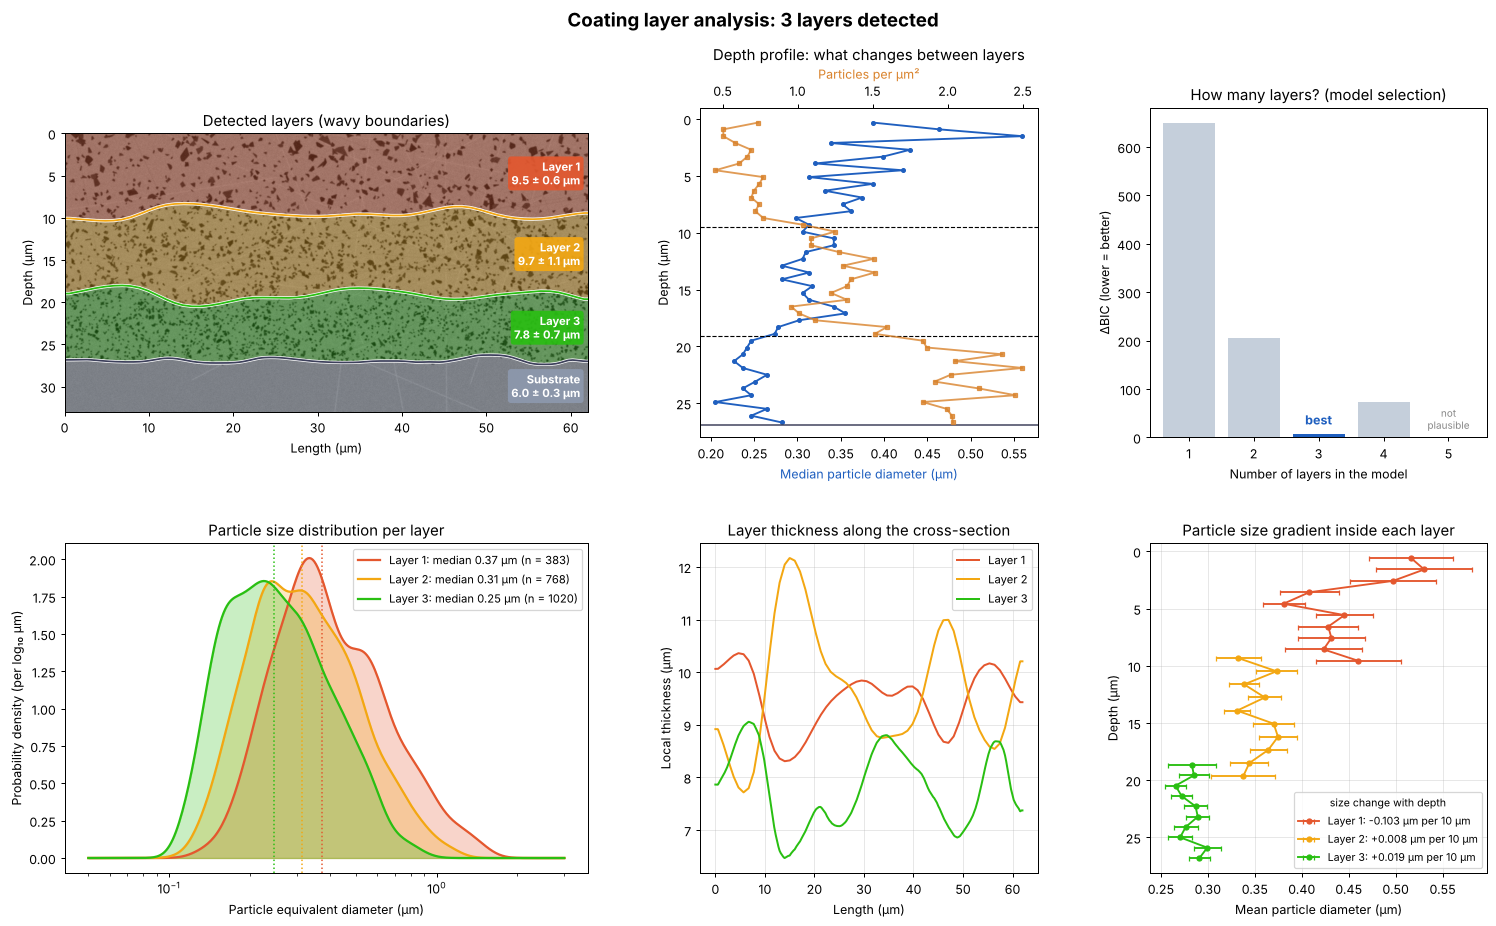

In [7]:
fig = plot_analysis(res)

In [8]:
res.layer_table()

,region,mean_thickness_um,thickness_std_um,min_thickness_um,max_thickness_um,area_um2,particles,mean_diameter_um,median_diameter_um,particle_area_fraction
0,Layer 1,9.5043,0.5655,8.3094,10.3616,589.8402,383,0.4506,0.3746,0.1331
1,Layer 2,9.6551,1.1378,7.7172,12.1691,599.1993,768,0.3547,0.3134,0.1574
2,Layer 3,7.7913,0.7233,6.4700,9.0584,483.5298,1020,0.2813,0.2466,0.1592
3,Substrate,6.0191,0.2580,5.5967,6.7050,373.5500,6,0.2333,0.2210,0.0016


## 6. Check against the ground truth

Boundary 1: mean error 0.42 µm
Boundary 2: mean error 0.60 µm


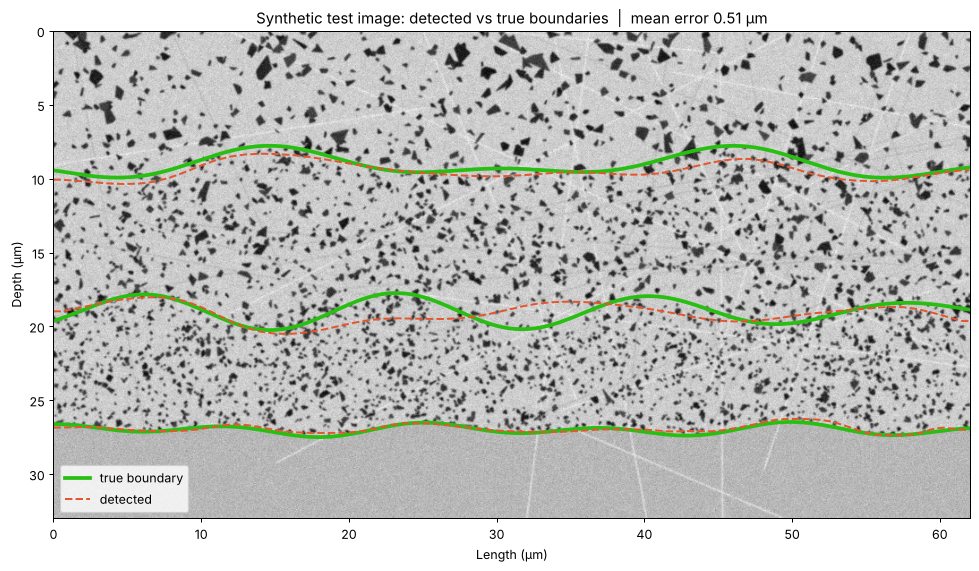

In [9]:
fig = plot_truth_comparison(res, truth)
for i in range(res.n_layers - 1):
    e = np.abs(res.curve(i) - truth["boundaries"][i]).mean() / PX_PER_UM
    print(f"Boundary {i + 1}: mean error {e:.2f} µm")

## 7. Validation on 100 unseen images
`validate.py` generates 100 new random cross-sections (1 to 4 layers, thickness 5 to 14 µm, different particle sizes and densities, size ratio between neighbouring layers 1.3 to 1.8) and compares the result with the known truth. A second experiment lowers the size difference between layers to find where the method stops working. Running it takes about 3 minutes; here the saved results are shown.

In [10]:
pd.read_csv("images/validation_summary.csv", index_col=0)

,value
images,100.00
layer count correct (%),95.00
"boundary error, median (µm)",0.66
"boundary error, 90th percentile (µm)",1.31
"substrate error, median (µm)",0.42


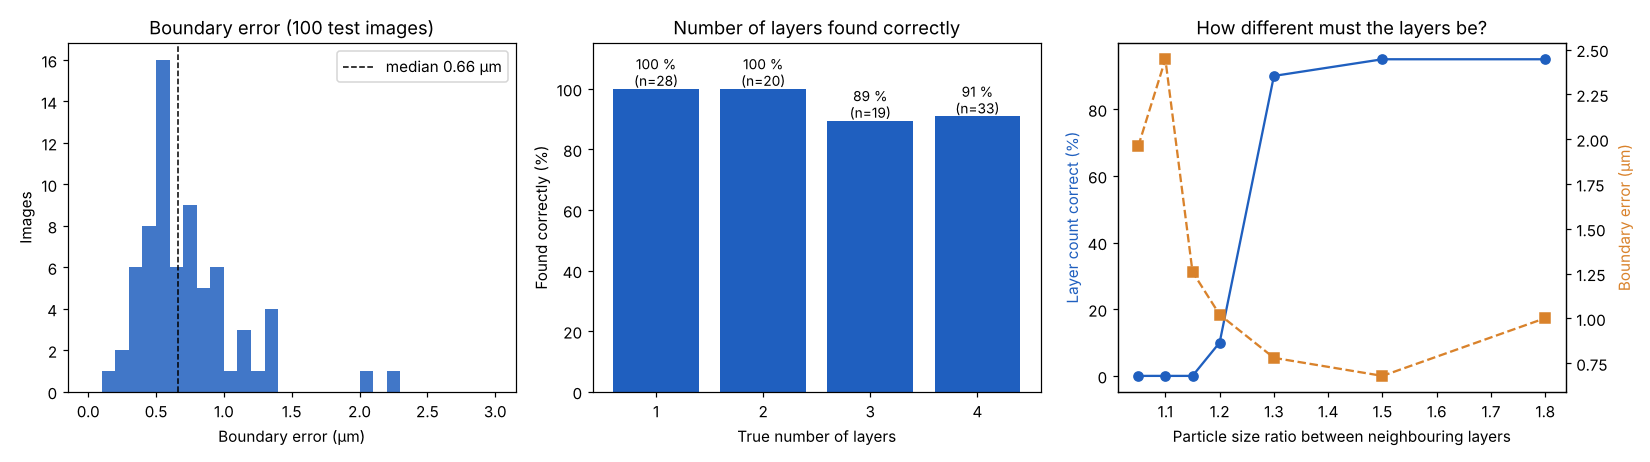

In [11]:
from IPython.display import Image
Image("images/validation.png")

## 8. Your own images
```python
from layer_analysis import Params, analyze, load_gray
from plot import plot_analysis

res = analyze(load_gray("my_cross_section.tif"), Params(px_per_um=16.5))  # 10 µm = 165 px
plot_analysis(res)
res.layer_table()            # thickness, area, particle statistics per layer
res.boundary_table()         # boundary depth along the cross-section
```
Or from the command line, for many images at once:
```
python analyze.py my_images/*.tif --px-per-um 16.5 --out results
```
If you already know the number of layers, pass `Params(n_layers=2)` or `--layers 2`.

## 9. Interactive app
Upload an image, enter the scale bar and download the results (figure + CSV). Uncomment and run:

In [12]:
# from app import build_app
# build_app().launch()      # opens http://127.0.0.1:7860